# Customer Churn Prediction
**Data Science Project** | Student: Juned Ansari | L. D. College of Engineering, Ahmedabad (GTU)

Dataset: Telco Customer Churn (Kaggle, BlastChar) – https://www.kaggle.com/datasets/blastchar/telco-customer-churn/data

**Note:** download `WA_Fn-UseC_-Telco-Customer-Churn.csv` from the link above and place it in the same folder as this notebook.

## 1. Setup and Data Loading

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)
sns.set_theme(style='whitegrid')
pal = {'No': '#4C78A8', 'Yes': '#E45756'}

df = pd.read_csv('dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 2. Data Preparation

### 2.1 Missing values, duplicates and data-type issues

In [3]:
print('Null cells        :', df.isna().sum().sum())
print('Duplicate rows    :', df.duplicated().sum())
print('Duplicate IDs     :', df.customerID.duplicated().sum())
blank = df.TotalCharges.astype(str).str.strip() == ''
print('Blank TotalCharges:', blank.sum())
print('Their tenure values:', df.loc[blank, 'tenure'].unique())

Null cells        : 0
Duplicate rows    : 0
Duplicate IDs     : 0
Blank TotalCharges: 11
Their tenure values: [0]


In [4]:
# Blank TotalCharges belong to customers with tenure = 0 (not yet billed) -> impute 0
df['TotalCharges'] = pd.to_numeric(df.TotalCharges.astype(str).str.strip().replace('', np.nan)).fillna(0)
df['y'] = (df.Churn == 'Yes').astype(int)
df[['tenure','MonthlyCharges','TotalCharges']].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


### 2.2 Outliers (IQR rule)

In [5]:
for c in ['tenure','MonthlyCharges','TotalCharges']:
    q1, q3 = df[c].quantile([.25, .75]); i = q3 - q1
    n = ((df[c] < q1 - 1.5*i) | (df[c] > q3 + 1.5*i)).sum()
    print(f'{c:15s} outliers: {n}')

tenure          outliers: 0
MonthlyCharges  outliers: 0
TotalCharges    outliers: 0


## 3. Exploratory Data Analysis

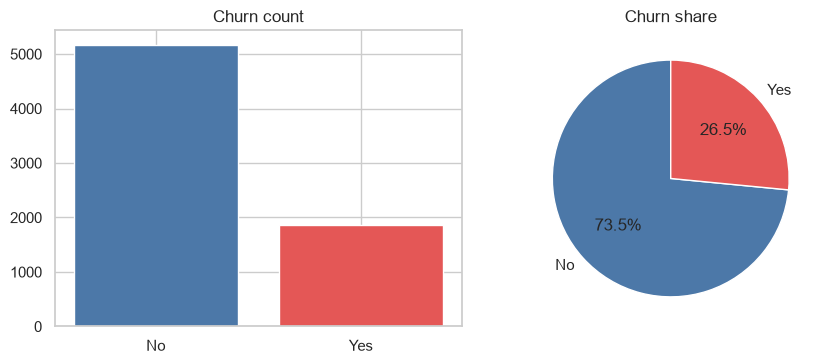

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
vc = df.Churn.value_counts()
ax[0].bar(vc.index, vc.values, color=[pal[i] for i in vc.index]); ax[0].set_title('Churn count')
ax[1].pie(vc.values, labels=vc.index, autopct='%1.1f%%', colors=[pal[i] for i in vc.index], startangle=90)
ax[1].set_title('Churn share'); plt.tight_layout(); plt.show()

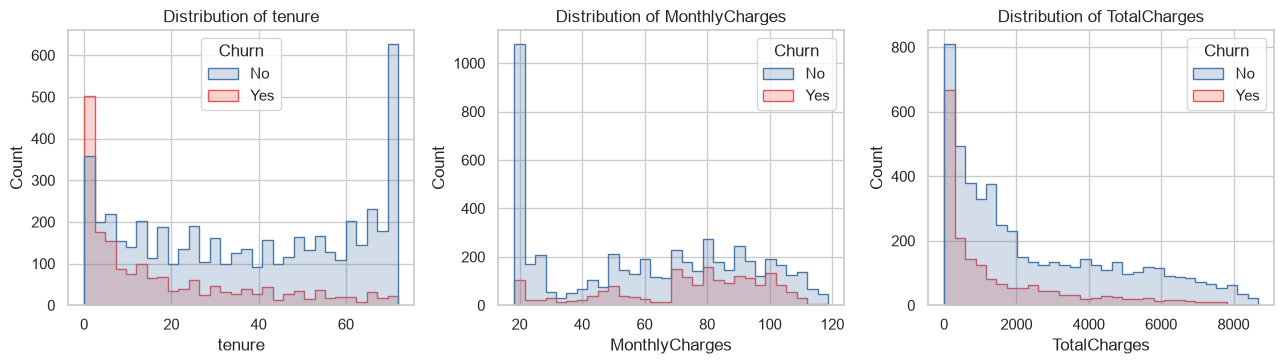

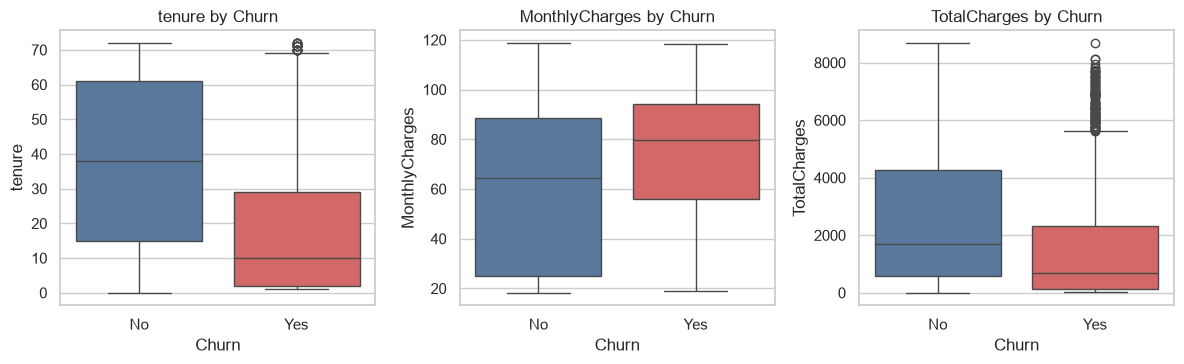

       tenure  MonthlyCharges  TotalCharges
Churn                                      
No      37.57           61.27       2549.91
Yes     17.98           74.44       1531.80


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, c in zip(ax, ['tenure','MonthlyCharges','TotalCharges']):
    sns.histplot(data=df, x=c, hue='Churn', palette=pal, bins=30, ax=a, element='step'); a.set_title(f'Distribution of {c}')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(12, 3.8))
for a, c in zip(ax, ['tenure','MonthlyCharges','TotalCharges']):
    sns.boxplot(data=df, x='Churn', y=c, hue='Churn', palette=pal, legend=False, ax=a); a.set_title(c + ' by Churn')
plt.tight_layout(); plt.show()
print(df.groupby('Churn')[['tenure','MonthlyCharges','TotalCharges']].mean().round(2))

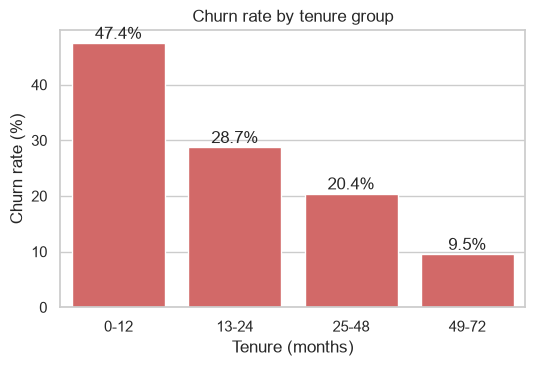

In [8]:
df['tenure_group'] = pd.cut(df.tenure, [-1,12,24,48,72], labels=['0-12','13-24','25-48','49-72'])
r = df.groupby('tenure_group', observed=True).y.mean()*100
plt.figure(figsize=(6, 3.6)); sns.barplot(x=r.index.astype(str), y=r.values, color='#E45756')
for i, v in enumerate(r.values): plt.text(i, v+.8, f'{v:.1f}%', ha='center')
plt.xlabel('Tenure (months)'); plt.ylabel('Churn rate (%)'); plt.title('Churn rate by tenure group'); plt.show()

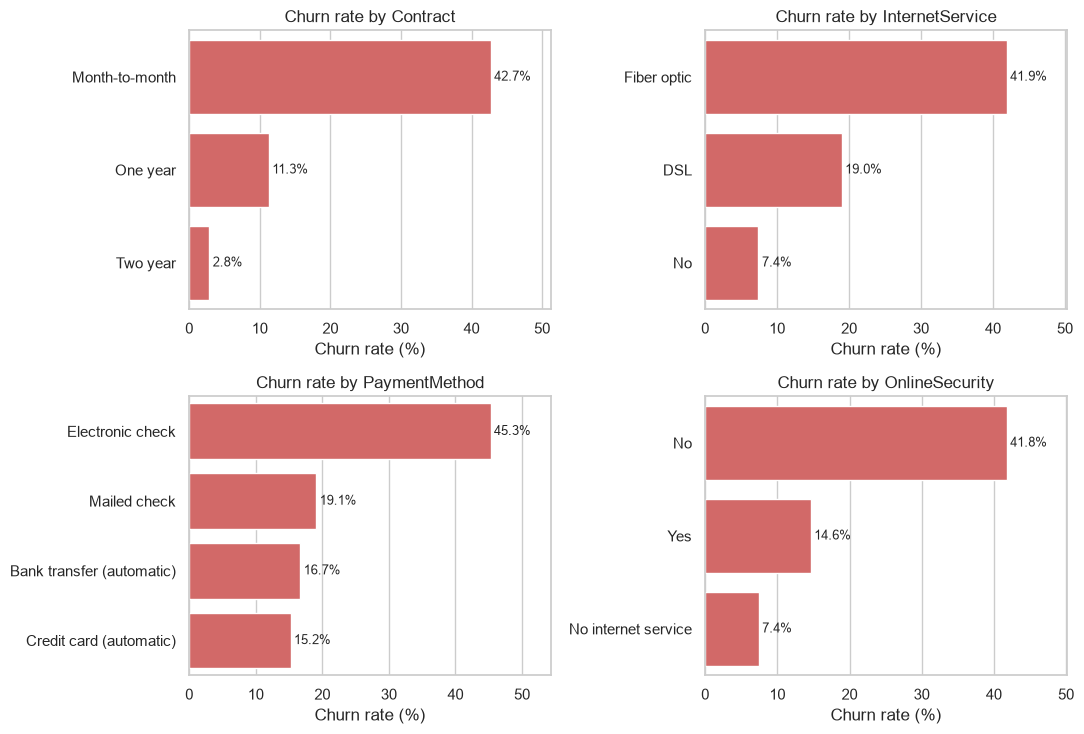

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7.5))
for a, c in zip(ax.ravel(), ['Contract','InternetService','PaymentMethod','OnlineSecurity']):
    r = df.groupby(c).y.mean().sort_values(ascending=False)*100
    sns.barplot(x=r.values, y=r.index, ax=a, color='#E45756'); a.set_xlabel('Churn rate (%)'); a.set_ylabel(''); a.set_title(f'Churn rate by {c}')
    for i, v in enumerate(r.values): a.text(v+.5, i, f'{v:.1f}%', va='center', fontsize=9)
    a.set_xlim(0, r.max()*1.2)
plt.tight_layout(); plt.show()

In [10]:
for c in ['TechSupport','PaperlessBilling','Partner','Dependents','gender','SeniorCitizen','PhoneService']:
    print((df.groupby(c).y.mean()*100).round(1).to_dict())

{'No': 41.6, 'No internet service': 7.4, 'Yes': 15.2}
{'No': 16.3, 'Yes': 33.6}
{'No': 33.0, 'Yes': 19.7}
{'No': 31.3, 'Yes': 15.5}
{'Female': 26.9, 'Male': 26.2}
{0: 23.6, 1: 41.7}
{'No': 24.9, 'Yes': 26.7}


## 4. Feature Engineering and Encoding

In [11]:
d = df.drop(columns=['customerID','Churn','tenure_group']).copy()
d['AvgChargePerMonth'] = np.where(d.tenure > 0, d.TotalCharges / d.tenure.replace(0, 1), d.MonthlyCharges)
svc = ['OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']
d['NumServices'] = sum((d[c] == 'Yes').astype(int) for c in svc)
for c in ['MultipleLines'] + svc:
    d[c] = d[c].replace({'No phone service': 'No', 'No internet service': 'No'})
for c in ['Partner','Dependents','PhoneService','PaperlessBilling','MultipleLines'] + svc:
    d[c] = (d[c] == 'Yes').astype(int)
d['gender'] = (d.gender == 'Male').astype(int)
d = pd.get_dummies(d, columns=['InternetService','Contract','PaymentMethod'], drop_first=True, dtype=int)
print(d.shape)
X, y = d.drop(columns='y'), d.y

(7043, 26)


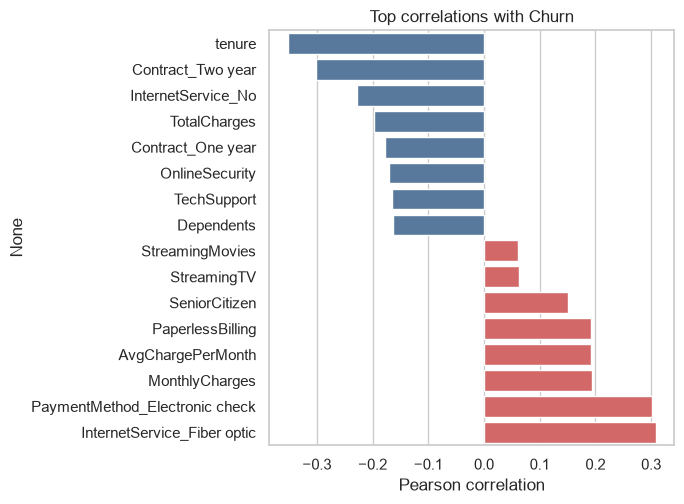

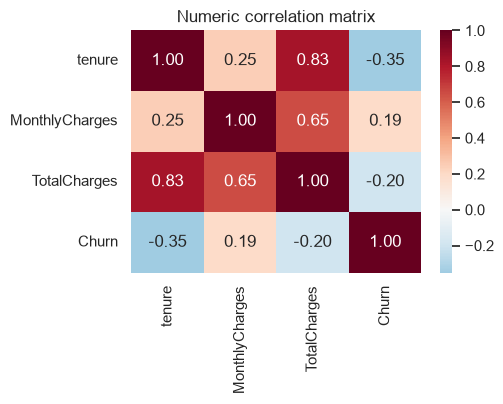

In [12]:
corr = d.corr()['y'].drop('y').sort_values()
top = pd.concat([corr.head(8), corr.tail(8)])
plt.figure(figsize=(7, 5.2))
sns.barplot(x=top.values, y=top.index, hue=top.index, legend=False, palette=['#4C78A8' if v < 0 else '#E45756' for v in top.values])
plt.title('Top correlations with Churn'); plt.xlabel('Pearson correlation'); plt.tight_layout(); plt.show()

plt.figure(figsize=(5.2, 4.2))
sns.heatmap(df[['tenure','MonthlyCharges','TotalCharges','y']].rename(columns={'y':'Churn'}).corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Numeric correlation matrix'); plt.tight_layout(); plt.show()

## 5. Train/Test Split and Scaling

In [13]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, stratify=y, random_state=42)
print(len(Xtr), len(Xte), ytr.mean().round(3), yte.mean().round(3))
num_cols = ['tenure','MonthlyCharges','TotalCharges','AvgChargePerMonth','NumServices']
sc = StandardScaler().fit(Xtr[num_cols])          # fit on training data only (no leakage)
Xtr_s, Xte_s = Xtr.copy(), Xte.copy()
Xtr_s[num_cols] = sc.transform(Xtr[num_cols]); Xte_s[num_cols] = sc.transform(Xte[num_cols])

5634 1409 0.265 0.265


## 6. Model Training and Evaluation

In [14]:
models = {
    'Logistic Regression': (LogisticRegression(max_iter=2000, class_weight='balanced'), True),
    'Decision Tree':       (DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42), False),
    'Random Forest':       (RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=5,
                                                   class_weight='balanced', random_state=42, n_jobs=-1), False),
    'Gradient Boosting':   (GradientBoostingClassifier(n_estimators=150, learning_rate=.05, max_depth=3, random_state=42), False)}
skf = StratifiedKFold(5, shuffle=True, random_state=42)
res, probs, fitted = [], {}, {}
for name, (m, scaled) in models.items():
    A, B = (Xtr_s, Xte_s) if scaled else (Xtr, Xte)
    m.fit(A, ytr); p = m.predict_proba(B)[:, 1]; pred = (p >= .5).astype(int)
    probs[name], fitted[name] = p, m
    res.append(dict(Model=name, Accuracy=accuracy_score(yte, pred), Precision=precision_score(yte, pred),
                    Recall=recall_score(yte, pred), F1=f1_score(yte, pred), ROC_AUC=roc_auc_score(yte, p),
                    CV_AUC=cross_val_score(m, A, ytr, cv=skf, scoring='roc_auc').mean()))
results = pd.DataFrame(res).round(3).set_index('Model'); results

,Accuracy,Precision,Recall,F1,ROC_AUC,CV_AUC
Model,,,,,,
Logistic Regression,0.738,0.504,0.781,0.613,0.842,0.845
Decision Tree,0.723,0.487,0.810,0.608,0.828,0.823
Random Forest,0.757,0.528,0.802,0.637,0.845,0.847
Gradient Boosting,0.798,0.656,0.500,0.568,0.844,0.848


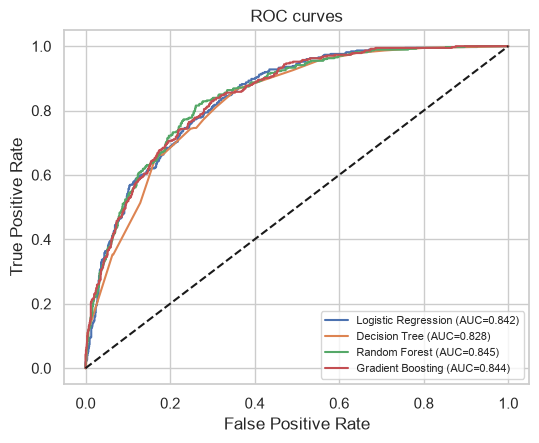

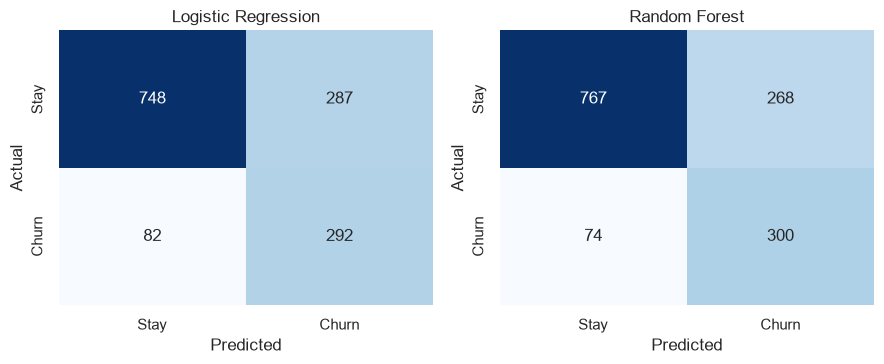

In [15]:
plt.figure(figsize=(6, 4.6))
for n, p in probs.items():
    f, t, _ = roc_curve(yte, p); plt.plot(f, t, label=f'{n} (AUC={roc_auc_score(yte, p):.3f})')
plt.plot([0,1], [0,1], 'k--'); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC curves'); plt.legend(loc='lower right', fontsize=8); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for a, n in zip(ax, ['Logistic Regression', 'Random Forest']):
    sns.heatmap(confusion_matrix(yte, (probs[n] >= .5).astype(int)), annot=True, fmt='d', cmap='Blues', cbar=False, ax=a,
                xticklabels=['Stay','Churn'], yticklabels=['Stay','Churn']); a.set_title(n); a.set_xlabel('Predicted'); a.set_ylabel('Actual')
plt.tight_layout(); plt.show()

## 7. Feature Importance and Coefficients

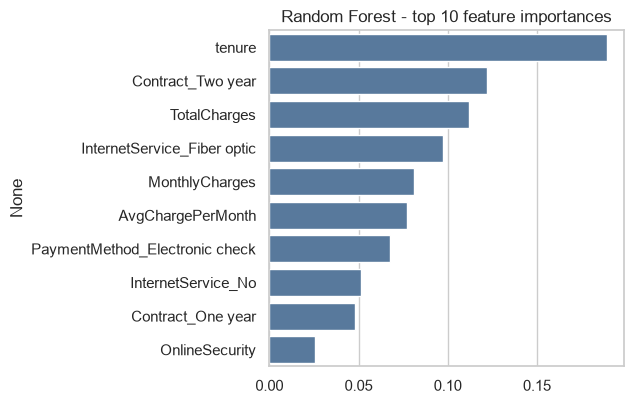

Strongest churn-reducing factors:
 Contract_Two year    -1.415
tenure               -1.150
InternetService_No   -1.097
Contract_One year    -0.717
dtype: float64 

Strongest churn-increasing factors:
 PaperlessBilling                  0.337
PaymentMethod_Electronic check    0.400
TotalCharges                      0.479
InternetService_Fiber optic       1.062
dtype: float64


In [16]:
imp = pd.Series(fitted['Random Forest'].feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
plt.figure(figsize=(6.5, 4.2)); sns.barplot(x=imp.values, y=imp.index, color='#4C78A8')
plt.title('Random Forest - top 10 feature importances'); plt.tight_layout(); plt.show()

coef = pd.Series(fitted['Logistic Regression'].coef_[0], index=X.columns).sort_values()
print('Strongest churn-reducing factors:\n', coef.head(4).round(3), '\n\nStrongest churn-increasing factors:\n', coef.tail(4).round(3))

## 8. Decision-Threshold Analysis (Logistic Regression)

In [17]:
rows = []
for t in [.3, .4, .5, .6]:
    pr = (probs['Logistic Regression'] >= t).astype(int)
    rows.append(dict(Threshold=t, Precision=precision_score(yte, pr), Recall=recall_score(yte, pr),
                     F1=f1_score(yte, pr), Accuracy=accuracy_score(yte, pr)))
pd.DataFrame(rows).round(3).set_index('Threshold')

,Precision,Recall,F1,Accuracy
Threshold,,,,
0.3,0.432,0.928,0.590,0.657
0.4,0.466,0.866,0.606,0.700
0.5,0.504,0.781,0.613,0.738
0.6,0.539,0.703,0.610,0.762


## 9. Conclusion
- **Best model:** Random Forest (highest ROC-AUC and F1); Logistic Regression is a close and more interpretable alternative.
- **Main churn drivers:** month-to-month contract, short tenure, Fiber optic service, electronic-check payment, and absence of security/support add-ons.
- **Next steps:** hyper-parameter tuning, XGBoost/LightGBM, SMOTE/cost-sensitive learning, SHAP explainability, customer segmentation and a Streamlit demo app.